## Using root

In [6]:
import uproot

file = uproot.open(
    "root://cmsxrootd.crc.nd.edu//store/user/apiccine/skimmed_SR/data/NAOD_ULv12_lepMVA-run3/2022/v260222/DoubleMuon_Run2022C_22Sep2023/output_170.root"
)

print(file.keys())

tree = file["Events"]

print(tree.keys())

import awkward as ak

events = tree.arrays(library="ak")

['Events;1', 'LuminosityBlocks;1', 'Runs;1', 'untagged;1']
['run', 'luminosityBlock', 'event', 'bunchCrossing', 'BeamSpot_type', 'BeamSpot_sigmaZ', 'BeamSpot_sigmaZError', 'BeamSpot_z', 'BeamSpot_zError', 'nboostedTau', 'boostedTau_idAntiEle2018', 'boostedTau_idAntiMu', 'boostedTau_idMVAnewDM2017v2', 'boostedTau_idMVAoldDM2017v2', 'boostedTau_jetIdx', 'boostedTau_rawAntiEleCat2018', 'boostedTau_charge', 'boostedTau_decayMode', 'boostedTau_chargedIso', 'boostedTau_eta', 'boostedTau_leadTkDeltaEta', 'boostedTau_leadTkDeltaPhi', 'boostedTau_leadTkPtOverTauPt', 'boostedTau_mass', 'boostedTau_neutralIso', 'boostedTau_phi', 'boostedTau_photonsOutsideSignalCone', 'boostedTau_pt', 'boostedTau_puCorr', 'boostedTau_rawAntiEle2018', 'boostedTau_rawIso', 'boostedTau_rawIsodR03', 'boostedTau_rawMVAnewDM2017v2', 'boostedTau_rawMVAoldDM2017v2', 'CaloMET_phi', 'CaloMET_pt', 'CaloMET_sumEt', 'ChsMET_phi', 'ChsMET_pt', 'ChsMET_sumEt', 'nCorrT1METJet', 'CorrT1METJet_area', 'CorrT1METJet_eta', 'CorrT1METJ

In [7]:
import uproot
import awkward as ak
import numpy as np
import hist
from hist import Hist
import vector
mask = ak.num(events.Muon_pt) >= 2
mu_pt = events.Muon_pt[mask]
mu_eta = events.Muon_eta[mask]
mu_phi = events.Muon_phi[mask]
mu_mass = events.Muon_mass[mask]

/users/ldiazlie/.conda/envs/coffea-env/lib/python3.9/site-packages/mplhep/_utils.py:1111: UserWarning: Integer weights indicate poissonian data. Will calculate Garwood interval if ``scipy`` is installed. Otherwise errors will be set to ``sqrt(w2)``.
  self.errors()


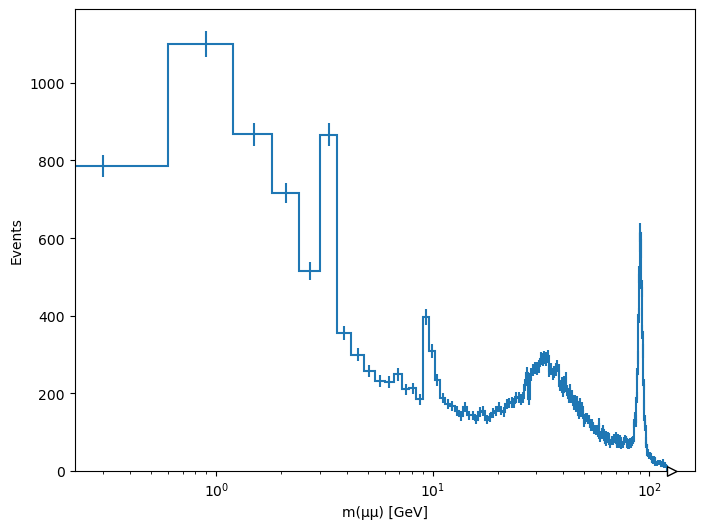

In [3]:
px1 = mu_pt[:,0] * np.cos(mu_phi[:,0])
py1 = mu_pt[:,0] * np.sin(mu_phi[:,0])
pz1 = mu_pt[:,0] * np.sinh(mu_eta[:,0])

px2 = mu_pt[:,1] * np.cos(mu_phi[:,1])
py2 = mu_pt[:,1] * np.sin(mu_phi[:,1])
pz2 = mu_pt[:,1] * np.sinh(mu_eta[:,1])

m_mu = 0.105

E1 = np.sqrt(px1**2 + py1**2 + pz1**2 + m_mu**2)
E2 = np.sqrt(px2**2 + py2**2 + pz2**2 + m_mu**2)
E = E1 + E2

px = px1 + px2
py = py1 + py2
pz = pz1 + pz2

masses = np.sqrt(E**2 - (px**2 + py**2 + pz**2))


import hist
from hist import Hist

h = (
    Hist.new
    .Reg(200, 0, 120, name="m", label="m(μμ) [GeV]")
    .Int64()
)

h.fill(masses)

import matplotlib.pyplot as plt
import mplhep as hep
# Plot
fig, ax = plt.subplots(figsize=(8, 6))

h.plot()

ax.set_xscale("log")   # 👈 aquí

ax.set_xlabel("m(μμ) [GeV]")
ax.set_ylabel("Events")


plt.show()

In [4]:
len(masses)

34348

## First Histogram with Coffea and hist

/users/ldiazlie/.conda/envs/coffea-env/lib/python3.9/site-packages/mplhep/_utils.py:1111: UserWarning: Integer weights indicate poissonian data. Will calculate Garwood interval if ``scipy`` is installed. Otherwise errors will be set to ``sqrt(w2)``.
  self.errors()


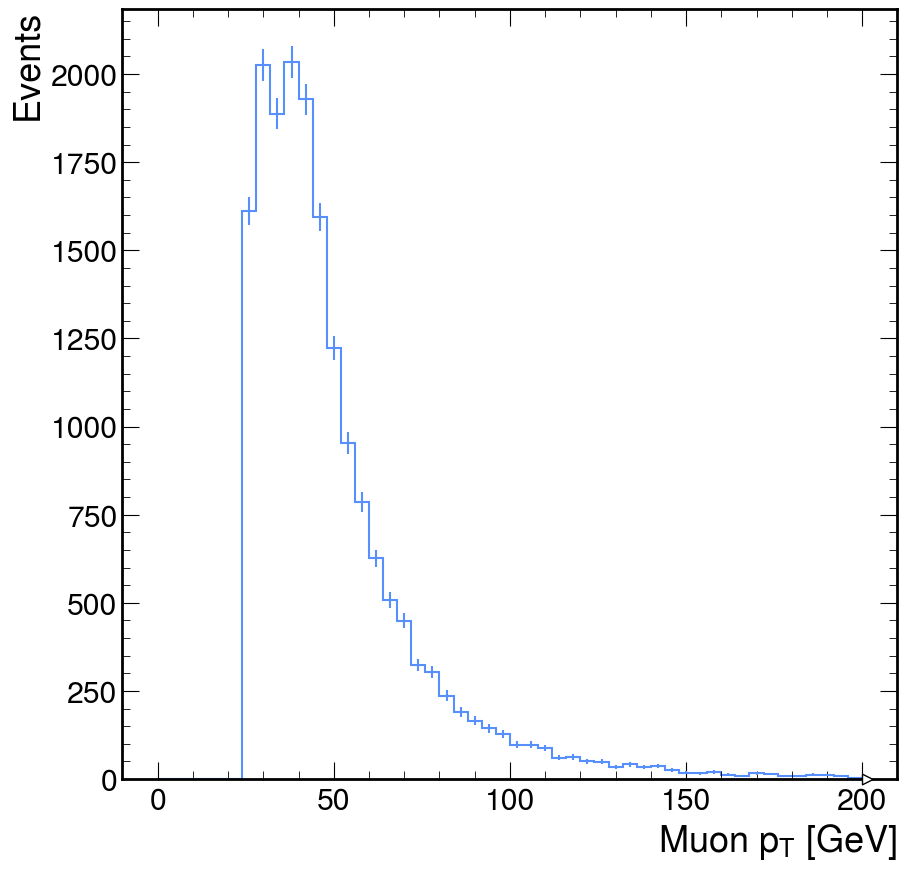

In [5]:
from coffea.nanoevents import NanoEventsFactory, NanoAODSchema
from hist import Hist
import hist
import awkward as ak
import matplotlib.pyplot as plt
import mplhep as hep

hep.style.use("CMS")

# Load events
events = NanoEventsFactory.from_root(
    "root://cmsxrootd.crc.nd.edu//store/user/apiccine/skimmed_SR/data/NAOD_ULv12_lepMVA-run3/2022/v260222/DoubleMuon_Run2022C_22Sep2023/output_170.root",
    schemaclass=NanoAODSchema,
).events()

# Trigger
events = events[events.HLT.IsoMu24]

# Muons
muons = events.Muon

good_muons = muons[
    (muons.pt > 25)
    & (abs(muons.eta) < 2.4)
    & muons.tightId
]

# Histogram
h_mu_pt = Hist(
    hist.axis.Regular(50, 0, 200, name="pt", label=r"Muon $p_T$ [GeV]")
)

# Fill
h_mu_pt.fill(
    pt=ak.flatten(good_muons.pt)
)

# Plot
fig, ax = plt.subplots()

h_mu_pt.plot()

ax.set_ylabel("Events")

plt.show()